# HISTORICAL / DEBUG NOTEBOOK — YOLO Spine-Keypoint Pipeline (old split)

> ## WARNING — OLD-SPLIT RESULTS, AFFECTED BY DATA LEAKAGE
> Every model result in this notebook was measured on the **old public train/valid/test split**. That split puts near-identical copies of the same photos in different splits: **25 of 36 validation images and 9 of 19 test images** have a near-identical copy elsewhere (section 2). The numbers are therefore **optimistic**.
>
> - **Do not use them as final performance claims.** They are for seeing what changed between models while debugging.
> - **Do not re-run this notebook with grouped-split results.** It is built for the old split only, and refuses results evaluated on another dataset.
> - **Final results** are in a separate notebook, [`grouped_workflow_comparison.ipynb`](grouped_workflow_comparison.ipynb): a model **retrained on the grouped train/valid split** and evaluated on its test folder (`Data/Processed/scoliosis_grouped_split/`). Those numbers are far less flattering — see that notebook.
>
> Models trained on the old split should not be interpreted as unbiased on the grouped test set.


**Project:** Kidzonia — AI-assisted scoliosis **screening support** (non-diagnostic)

This notebook is the *visual evidence* behind the written summary in [`docs/interim_report.md`](docs/interim_report.md). It holds the charts, tables and example images; the report holds the explanation.

**What the pipeline does**

```
photo  →  YOLOv8-pose (12 spine keypoints + normal/scoliosis class)
       →  anatomy-aware geometry checks   (src/FeatureExtraction/spine_geometry.py)
       →  reliability score + "retake / review" flag
```

The reliability checks describe **measurement quality** — can the keypoints be trusted? — not disease. Nothing here is a diagnosis, a Cobb angle, or an angle-of-trunk-rotation measurement.

**Contents:** 1 Dataset · 2 Is the test set trustworthy? · 3 Models compared · 4 Test results · 5 Visual examples · 6 Interpretation · 7 Limitations

In [1]:
import sys, subprocess, yaml
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

ROOT = Path().resolve()
sys.path.insert(0, str(ROOT))
EVAL_DIR = ROOT / 'Data' / 'Processed' / 'evaluation'
COMP_DIR = ROOT / 'Data' / 'Processed' / 'comparison'

pd.set_option('display.width', 140)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})

# label -> (evaluation tag, folders the training run may live in, plot colour)
MODELS = {
    'Original data':             ('original_trained',    [ROOT / 'models/yolo_scoliosis/run'],                                                  '#DD8452'),
    'Cleaned data':              ('cleaned_trained',     [ROOT / 'models/yolo_scoliosis_cleaned/run', ROOT / 'runs/pose/models/yolo_scoliosis_cleaned/run'], '#4C72B0'),
    'Cleaned + conservative aug': ('cleaned_aug_trained', [ROOT / 'models/yolo_scoliosis_cleaned_aug/run'],                                     '#55A868'),
}

def run_dir(label):
    for d in MODELS[label][1]:
        if (d / 'weights' / 'best.pt').exists():
            return d
    return None

results = {}   # per-image test results for every model that has been trained AND evaluated
for label, (tag, _, _) in MODELS.items():
    path = COMP_DIR / f'yolo_finetuned_scoliosis_test_{tag}.csv'
    if path.exists():
        results[label] = pd.read_csv(path)
COLORS = {label: MODELS[label][2] for label in MODELS}
print('Models with test results:', list(results))

# Guard: this notebook is for OLD-split results only. Refuse any results evaluated on another dataset/split
# (grouped-split results belong in grouped_workflow_comparison.ipynb).
from src.Evaluation.dataset_paths import read_meta, is_legacy_eval
for label, (tag, _, _) in MODELS.items():
    meta = read_meta(COMP_DIR / f'yolo_finetuned_scoliosis_test_{tag}.csv')
    if label in results and not is_legacy_eval(meta):
        raise RuntimeError(f'{label}: evaluated on {meta.get("eval_dataset")}/{meta.get("eval_split")}, not the old split. '
                           'Put grouped-split results in grouped_workflow_comparison.ipynb, not in this historical notebook.')

missing = [l for l in MODELS if l not in results]
if missing:
    print('Not available yet (train + evaluate them to add them to every chart below):', missing)

Models with test results: ['Original data', 'Cleaned data', 'Cleaned + conservative aug']


## 1. Dataset: original vs cleaned

Source: public Roboflow scoliosis keypoint dataset (CC BY 4.0), 12 spine keypoints per image, classes `normal` / `scoliosis`.
`dataset_cleaning.py` removes only **objective** label defects (empty labels, keypoints outside the image). Hard-looking or unusual images are kept on purpose.

In [2]:
split = pd.read_csv(EVAL_DIR / 'split_quality_summary.csv')
sizes = split.pivot(index='dataset', columns='split', values='images')[['train', 'valid', 'test']]
sizes['total'] = sizes.sum(axis=1)
display(sizes.loc[['original', 'cleaned']].rename_axis('dataset'))

removed = pd.read_csv(ROOT / 'Data/Processed/scoliosis_cleaned/excluded_samples.csv')
removed['issue'] = removed['issues'].str.split(':').str[0].str.split(';').str[0]
print(f'Removed by cleaning: {len(removed)} of {int(sizes.loc["original", "total"])} images')
display(removed.groupby(['issue', 'split']).size().unstack(fill_value=0))

split,train,valid,test,total
dataset,,,,
original,135,37,19,191
cleaned,128,36,19,183


Removed by cleaning: 8 of 191 images


split,train,valid
issue,,
empty_label_file,4,1
keypoint_out_of_range,3,0


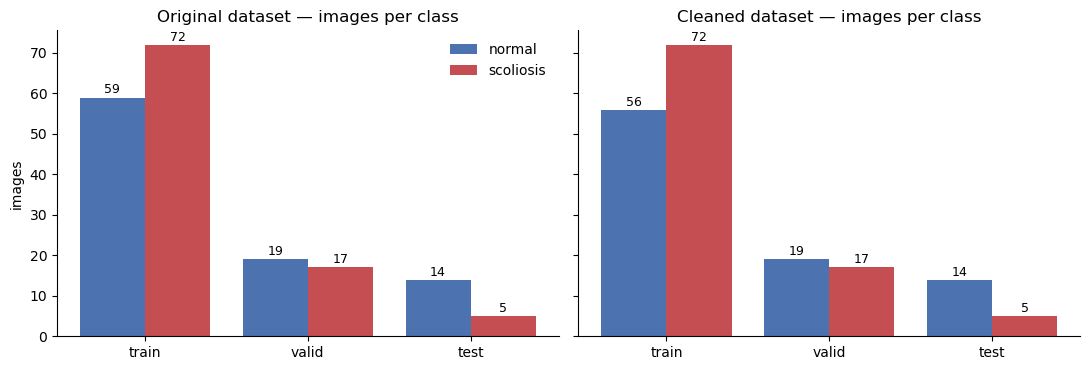

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, name in zip(axes, ['original', 'cleaned']):
    d = split[split.dataset == name].set_index('split').loc[['train', 'valid', 'test']]
    x = np.arange(3)
    ax.bar(x - 0.2, d['normal'], 0.4, label='normal', color='#4C72B0')
    ax.bar(x + 0.2, d['scoliosis'], 0.4, label='scoliosis', color='#C44E52')
    for i, (n, s) in enumerate(zip(d['normal'], d['scoliosis'])):
        ax.text(i - 0.2, n + 1, n, ha='center', fontsize=9); ax.text(i + 0.2, s + 1, s, ha='center', fontsize=9)
    ax.set_xticks(x, ['train', 'valid', 'test']); ax.set_title(f'{name.capitalize()} dataset — images per class')
axes[0].set_ylabel('images'); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

## 2. Is the test set trustworthy?

The dataset has several copies of the same photo (same filename before `.rf.`, or near-identical pixels under another name). If a copy sits in `train` and another in `test`, the model is partly tested on images it has effectively seen. `split_quality_check.py` measures this.

,images,images with a near-duplicate in another split,share_with_near_duplicate_elsewhere_%
split,,,
train,128,33,26
valid,36,25,69
test,19,9,47


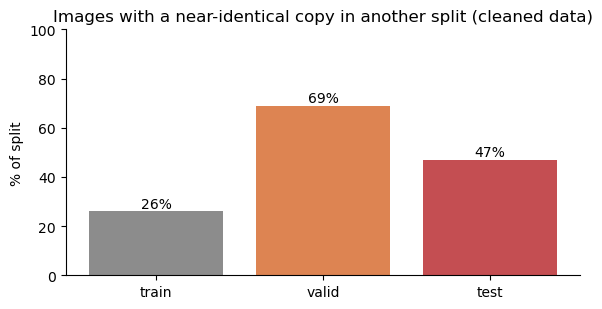

In [4]:
leak = split[['dataset', 'split', 'images', 'images_with_near_duplicate_in_other_split']].copy()
leak['share_with_near_duplicate_elsewhere_%'] = (100 * leak.iloc[:, 3] / leak['images']).round(0).astype(int)
display(leak[leak.dataset == 'cleaned'].set_index('split').drop(columns='dataset')
        .rename(columns={'images_with_near_duplicate_in_other_split': 'images with a near-duplicate in another split'}))

d = leak[leak.dataset == 'cleaned'].set_index('split').loc[['train', 'valid', 'test']]
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(d.index, d['share_with_near_duplicate_elsewhere_%'], color=['#8C8C8C', '#DD8452', '#C44E52'])
for i, v in enumerate(d['share_with_near_duplicate_elsewhere_%']): ax.text(i, v + 1.5, f'{v}%', ha='center')
ax.set_ylim(0, 100); ax.set_ylabel('% of split'); ax.set_title('Images with a near-identical copy in another split (cleaned data)')
plt.tight_layout(); plt.show()

In [5]:
from src.Evaluation.split_quality_check import DATASETS, SPLITS, list_split, near_duplicate_pairs

records = [r for s in SPLITS for r in list_split(DATASETS['cleaned'], s)]
leaked_test = set()
for i, j, _ in near_duplicate_pairs(records):
    a, b = records[i], records[j]
    if {a['split'], b['split']} >= {'test'} and a['split'] != b['split']:
        leaked_test.add(a['stem'] if a['split'] == 'test' else b['stem'])

rows = []
for label, df in results.items():
    for name, part in (('test images with a near-duplicate in train/valid', df[df.capture_id.isin(leaked_test)]),
                       ('test images WITHOUT one (cleaner estimate)',       df[~df.capture_id.isin(leaked_test)])):
        pred = part.dropna(subset=['predicted_class'])
        rows.append({'model': label, 'test subset': name, 'images': len(part),
                     'correct': int(pred.classification_correct.sum()), 'predicted': len(pred),
                     'accuracy': round(pred.classification_correct.mean(), 3) if len(pred) else None})
display(pd.DataFrame(rows).set_index(['model', 'test subset']))
print('Small subsets (9–10 images): indicative only.')

images  correct  predicted  accuracy
model                      test subset                                                                           
Original data              test images with a near-duplicate in train/valid       9        7          7     1.000
                           test images WITHOUT one (cleaner estimate)            10        5          9     0.556
Cleaned data               test images with a near-duplicate in train/valid       9        9          9     1.000
                           test images WITHOUT one (cleaner estimate)            10        8         10     0.800
Cleaned + conservative aug test images with a near-duplicate in train/valid       9        8          9     0.889
                           test images WITHOUT one (cleaner estimate)            10        8         10     0.800

Small subsets (9–10 images): indicative only.


## 3. Models compared

> **WARNING — old-split results, affected by data leakage.** Near-identical copies of the same photos sit in train, valid and test (section 2), so the numbers here are optimistic. Historical/debug only — not a final performance claim.

All models are `yolov8n-pose` fine-tuned from the same pretrained weights; only the **training data** and **augmentation** differ. Settings below are read from each run's own `args.yaml`.

In [6]:
KEYS = ['data', 'epochs', 'patience', 'imgsz', 'batch', 'seed', 'fliplr', 'mosaic', 'degrees', 'translate', 'scale', 'hsv_v', 'erasing']
setup, epochs_run = {}, {}
for label in results:
    d = run_dir(label)
    if d is None:
        continue
    args = yaml.safe_load((d / 'args.yaml').read_text(encoding='utf-8'))
    row = {k: args.get(k) for k in KEYS}
    row['data'] = Path(str(row['data'])).name
    setup[label] = row
    epochs_run[label] = len(pd.read_csv(d / 'results.csv'))
setup_df = pd.DataFrame(setup)
setup_df.loc['epochs actually run'] = pd.Series(epochs_run)
display(setup_df)
print('fliplr = chance a training image is mirrored.  Note: the dataset\'s flip_idx is the identity, but kp9/kp10 are left/right shoulders —')
print('a mirrored image therefore keeps each shoulder label on the wrong side (see report). The conservative profile switches flipping off.')

,Original data,Cleaned data,Cleaned + conservative aug
data,scoliosis_train.yaml,scoliosis_cleaned.yaml,scoliosis_cleaned.yaml
epochs,100,100,100
patience,20,20,20
imgsz,640,640,640
batch,8,8,8
seed,0,0,0
fliplr,0.5,0.5,0.0
mosaic,1.0,1.0,0.0
degrees,0.0,0.0,5.0
translate,0.1,0.1,0.05


fliplr = chance a training image is mirrored.  Note: the dataset's flip_idx is the identity, but kp9/kp10 are left/right shoulders —
a mirrored image therefore keeps each shoulder label on the wrong side (see report). The conservative profile switches flipping off.


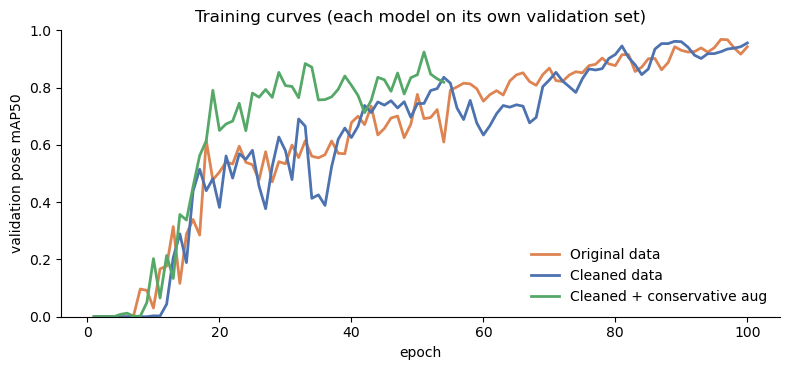

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for label in results:
    d = run_dir(label)
    if d is None:
        continue
    r = pd.read_csv(d / 'results.csv'); r.columns = [c.strip() for c in r.columns]
    ax.plot(r['epoch'], r['metrics/mAP50(P)'], label=label, color=COLORS[label], lw=2)
ax.set_xlabel('epoch'); ax.set_ylabel('validation pose mAP50'); ax.set_ylim(0, 1)
ax.set_title('Training curves (each model on its own validation set)'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 4. Test results

> **WARNING — old-split results, affected by data leakage.** Near-identical copies of the same photos sit in train, valid and test (section 2), so the numbers here are optimistic. Historical/debug only — not a final performance claim.

Same 19 test images for every model. Measurement-quality metrics come first; classification accuracy is secondary because 19 images (5 scoliosis) is a very small test set.

In [8]:
def summarise(df):
    flags = df['anatomy_warning_flags'].fillna('')
    pred = df.dropna(subset=['predicted_class'])
    scoli = df[df.ground_truth_class == 'scoliosis'].dropna(subset=['predicted_class'])
    return {
        'Test images':                                len(df),
        'Images with a prediction':                   len(pred),
        'Mean keypoint confidence':                   round(df.mean_confidence.mean(), 3),
        'Valid spine geometry (%)':                   round(100 * df.valid_spine_geometry.mean(), 1),
        'Mean anatomy reliability score':             round(df.anatomy_reliability_score.mean(), 3),
        'Curvature features reliable (%)':            round(100 * df.curvature_features_reliable.mean(), 1),
        'Shoulder warnings, of images with geometry (%)': round(100 * flags[df.valid_spine_geometry == True].str.contains('shoulder').mean(), 1),
        'Retake/review recommended (%)':              round(100 * df.retake_or_review_recommended.mean(), 1),
        'Classification accuracy (predicted only)':   round(pred.classification_correct.mean(), 3),
        'Accuracy, missed detections count as wrong': round(pred.classification_correct.sum() / len(df), 3),
        'Scoliosis recall':                           round((scoli.predicted_class == 'scoliosis').mean(), 3),
    }

metrics = pd.DataFrame({label: summarise(df) for label, df in results.items()})
display(metrics)

,Original data,Cleaned data,Cleaned + conservative aug
Test images,19.000,19.000,19.000
Images with a prediction,16.000,19.000,19.000
Mean keypoint confidence,0.712,0.887,0.966
Valid spine geometry (%),84.200,100.000,100.000
Mean anatomy reliability score,0.604,0.723,0.995
Curvature features reliable (%),84.200,100.000,100.000
"Shoulder warnings, of images with geometry (%)",100.000,100.000,0.000
Retake/review recommended (%),100.000,100.000,0.000
Classification accuracy (predicted only),0.750,0.895,0.842
"Accuracy, missed detections count as wrong",0.632,0.895,0.842


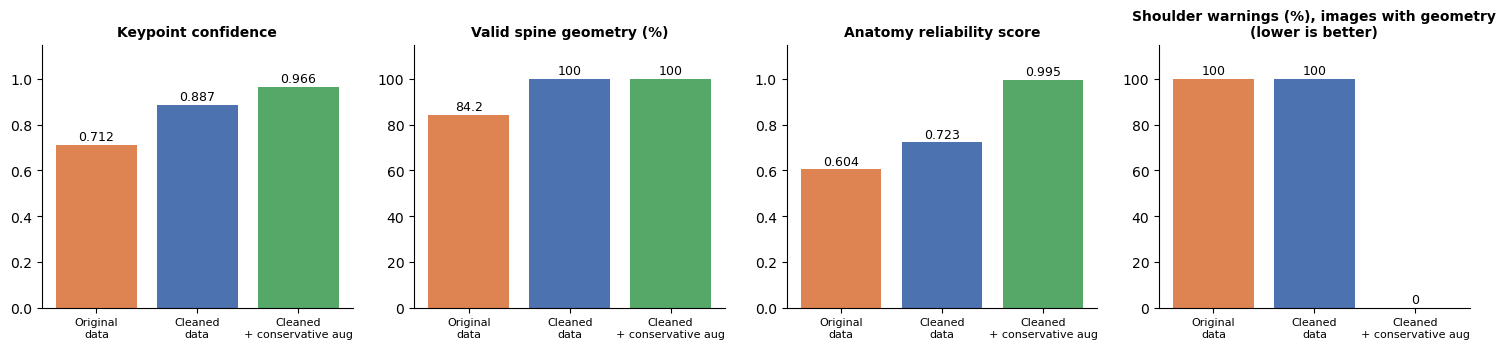

In [9]:
panels = [('Mean keypoint confidence', 'Keypoint confidence', 1), ('Valid spine geometry (%)', 'Valid spine geometry (%)', 100),
          ('Mean anatomy reliability score', 'Anatomy reliability score', 1), ('Shoulder warnings, of images with geometry (%)', 'Shoulder warnings (%), images with geometry\n(lower is better)', 100)]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (key, title, top) in zip(axes, panels):
    vals = [metrics.loc[key, l] for l in metrics.columns]
    bars = ax.bar(range(len(vals)), vals, color=[COLORS[l] for l in metrics.columns])
    for b, v in zip(bars, vals): ax.text(b.get_x() + b.get_width() / 2, v + top * 0.02, f'{v:g}', ha='center', fontsize=9)
    ax.set_xticks(range(len(vals)), [l.replace(' + ', '\n+ ').replace(' data', '\ndata') for l in metrics.columns], fontsize=8)
    ax.set_ylim(0, top * 1.15); ax.set_title(title, fontsize=10, fontweight='bold')
plt.tight_layout(); plt.show()

reliability_level,high,medium,low,invalid
Original data,0,16,0,3
Cleaned data,0,19,0,0
Cleaned + conservative aug,19,0,0,0


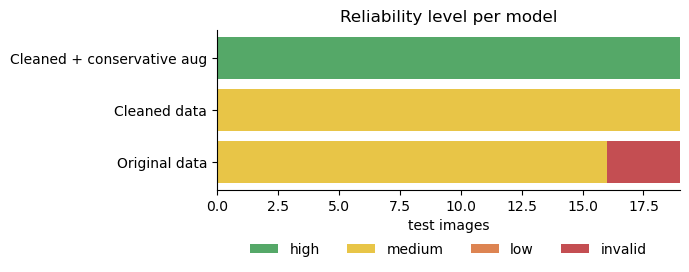

In [10]:
levels = ['high', 'medium', 'low', 'invalid']
level_colors = {'high': '#55A868', 'medium': '#E8C547', 'low': '#DD8452', 'invalid': '#C44E52'}
dist = pd.DataFrame({l: df.reliability_level.value_counts().reindex(levels, fill_value=0) for l, df in results.items()}).T
display(dist)

fig, ax = plt.subplots(figsize=(7, 3))
left = np.zeros(len(dist))
for lvl in levels:
    ax.barh(dist.index, dist[lvl], left=left, color=level_colors[lvl], label=lvl); left += dist[lvl].values
ax.set_xlabel('test images'); ax.set_title('Reliability level per model'); ax.legend(ncol=4, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.25))
plt.tight_layout(); plt.show()

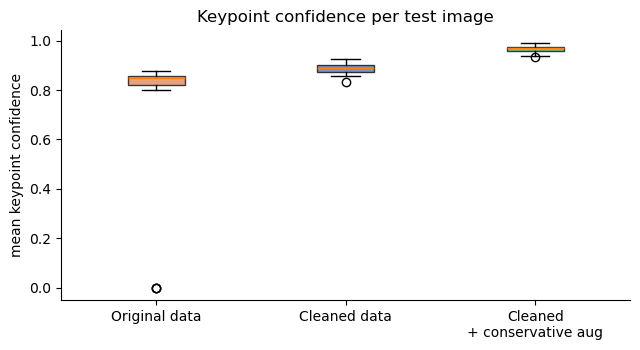

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
data = [results[l].mean_confidence.dropna() for l in results]
bp = ax.boxplot(data, tick_labels=[l.replace(' + ', '\n+ ') for l in results], patch_artist=True)
for patch, l in zip(bp['boxes'], results): patch.set_facecolor(COLORS[l]); patch.set_alpha(0.75)
ax.set_ylabel('mean keypoint confidence'); ax.set_title('Keypoint confidence per test image')
plt.tight_layout(); plt.show()

## 5. Visual examples

> **WARNING — old-split results, affected by data leakage.** Near-identical copies of the same photos sit in train, valid and test (section 2), so the numbers here are optimistic. Historical/debug only — not a final performance claim.

Overlays are generated by `debug_spine_geometry.py` (prediction: spine axis yellow, intermediate points blue, shoulder line magenta, with the geometry layer's verdict in text). Ground truth is drawn from the dataset labels (base/top green, shoulders magenta, neck/head yellow).

In [12]:
import cv2
from src.Evaluation.dataset_eda import draw_overlay, parse_label_file, imdecode_unicode

def make_overlays(label, stems):
    # run the debug script for any overlay that does not exist yet; returns the folder
    out_dir = ROOT / 'Data' / 'Processed' / 'geometry_debug' / MODELS[label][0]
    todo = [s for s in stems if not (out_dir / f'{s}_geometry.jpg').exists()]
    if todo:
        subprocess.run([sys.executable, str(ROOT / 'src/Evaluation/debug_spine_geometry.py'), '--weights', str(run_dir(label) / 'weights/best.pt'),
                        '--out-dir', str(out_dir), '--stems', *todo], cwd=ROOT, capture_output=True)
    return out_dir

def gt_overlay(stem):
    # ground-truth keypoints from the dataset label, drawn on the test image
    test_dir = ROOT / 'public_datasets' / 'scoliosis' / 'test'
    img = imdecode_unicode(next((test_dir / 'images').glob(f'{stem}.*')))
    objects = parse_label_file(test_dir / 'labels' / f'{stem}.txt', {0, 1})['objects']
    return cv2.cvtColor(draw_overlay(img, objects), cv2.COLOR_BGR2RGB)

def show(rows, columns, title):
    # rows: list of (stem, row-label); columns: list of (header, function(stem) -> image array)
    fig, axes = plt.subplots(len(rows), len(columns), figsize=(4.6 * len(columns), 4.6 * len(rows)), squeeze=False)
    for r, (stem, tag) in enumerate(rows):
        for c, (header, fn) in enumerate(columns):
            axes[r, c].imshow(fn(stem)); axes[r, c].axis('off')
            axes[r, c].set_title(f'{header}' + (f'\n{tag}' if c == 0 else ''), fontsize=9)
    plt.suptitle(title, y=0.995); plt.tight_layout(); plt.show()

best = [l for l in ('Cleaned + conservative aug', 'Cleaned data', 'Original data') if l in results][0]
before = 'Cleaned data' if best != 'Cleaned data' and 'Cleaned data' in results else None
valid = results[best][results[best].valid_spine_geometry == True].sort_values('anatomy_reliability_score', ascending=False)

### Before vs after (same test images)

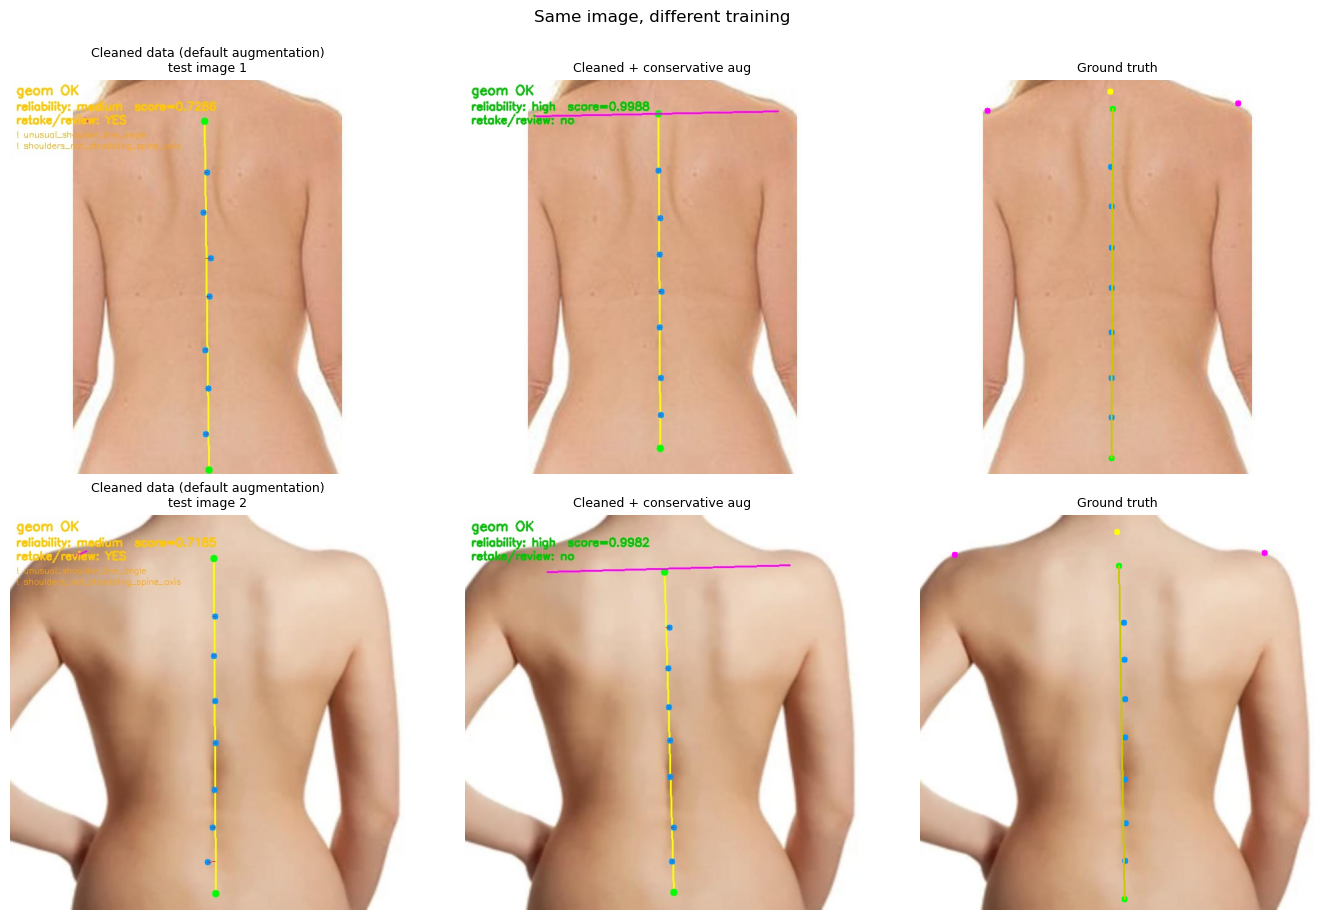

In [13]:
stems = list(valid.capture_id.head(2))
cols = []
if before:
    d_before = make_overlays(before, stems)
    cols.append((f'{before} (default augmentation)', lambda s: mpimg.imread(d_before / f'{s}_geometry.jpg')))
d_best = make_overlays(best, stems)
cols.append((f'{best}', lambda s: mpimg.imread(d_best / f'{s}_geometry.jpg')))
cols.append(('Ground truth', gt_overlay))
show([(s, f'test image {i + 1}') for i, s in enumerate(stems)], cols, 'Same image, different training')

### Least reliable cases for the best model

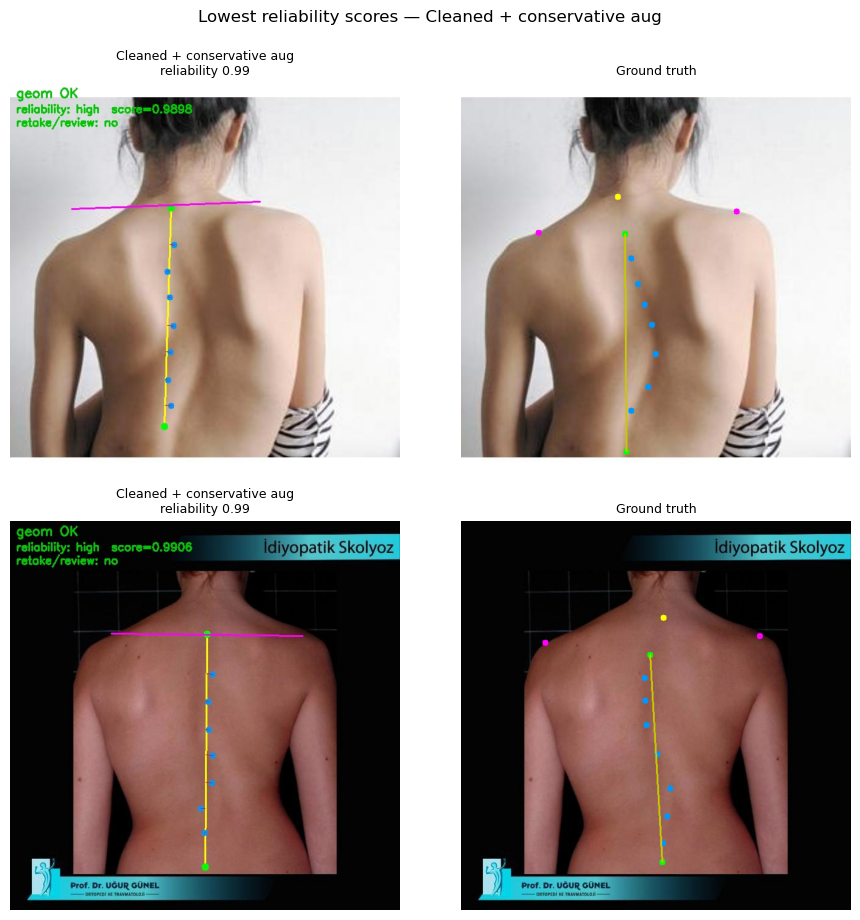

In [14]:
worst = valid.sort_values('anatomy_reliability_score').head(2)
stems = list(worst.capture_id)
d_best = make_overlays(best, stems)
show([(s, f'reliability {sc:.2f}') for s, sc in zip(worst.capture_id, worst.anatomy_reliability_score)],
     [(best, lambda s: mpimg.imread(d_best / f'{s}_geometry.jpg')), ('Ground truth', gt_overlay)], f'Lowest reliability scores — {best}')

## 6. Interpretation

> **WARNING — old-split results, affected by data leakage.** Near-identical copies of the same photos sit in train, valid and test (section 2), so the numbers here are optimistic. Historical/debug only — not a final performance claim.

**What improved**
- **Original → cleaned data:** keypoint confidence rose (0.71 → 0.89), valid spine geometry went from 84% to 100% (the original-data model missed 3 of 19 test images entirely), and the reliability score rose (0.60 → 0.72).
- **Cleaned → cleaned + conservative augmentation:** the shoulder problem went away. Shoulder warnings fell from 100% to 0% of images, retake/review from 100% to 0%, and all 19 test images reach `high` reliability (mean score 0.72 → 0.99). The median shoulder-line angle went from about 150° to about 2° — the shoulders now sit on the correct sides of the spine. Keypoint confidence rose again (0.89 → 0.97).

**What did not improve**
- **Classification accuracy slipped:** 0.90 → 0.84 (17/19 → 16/19). All three errors are normal images predicted as scoliosis (false positives); scoliosis recall is still 5/5. One image is a very small change on a 19-image test set, so this is a "no clear difference", not a finding.
- On the 10 test images with **no** near-identical copy in train/valid, accuracy is 8/10 for both models. The 9 images with a copy: 9/9 → 8/9.

**Why the shoulder problem went away (and the caveat)**
Default training mirrored half the images while the dataset's `flip_idx` is the identity, so kp9/kp10 (left/right shoulders) kept their labels on the wrong side after a mirror. The conservative profile turns flipping off. That fits the result, but **the conservative profile also changed other things at once** (no mosaic, no colour changes, milder scale/translation, small rotation), and this is **one training run**. The cause is therefore likely, not proven; an ablation (default augmentation with a corrected `flip_idx`, or `--augment-profile none`) would isolate it.

**Current best workflow:** *cleaned data + conservative augmentation* — the first model with trustworthy shoulder geometry. It is not a validated result: accuracy is below the 95% target and uncertain because of the small, leaky test set, and a reliability score near 1.0 on 19 images says the geometry is plausible, not that it is clinically accurate.

## 7. Limitations

- **Small dataset and test set** — 183 usable images from about 118 distinct photos; 19 test images (5 scoliosis). One or two predictions move accuracy by 5–10 points.
- **Split leakage** — near-identical copies of the same photo sit in train, valid and test (section 2). Test and validation numbers are optimistic until the data is re-split by photo.
- **Label quality** — public, non-clinical labels; at least two near-identical photos carry conflicting normal/scoliosis labels (see `split_quality_report_cleaned.md`).
- **No clinical validation** — outputs are screening-support indicators, not a diagnosis, Cobb angle, or angle of trunk rotation.
- **Not yet tested** — occlusion, clothing, lighting and other real-world variation are deliberately postponed (they can make image/label pairs invalid); the clinical photos here are not the RGB-D captures the deployed system will see.
- **Single training run per model** — no repeated seeds and no k-fold yet, so run-to-run training noise is not separated from real differences.
- **This notebook is historical.** Final, leakage-free results are in `grouped_workflow_comparison.ipynb` (model retrained on the grouped split).
